## Machine Learning Week-1 Notebook

### Table of Contents


##### 1. Intro to Machine Learning
##### 2. Supervised Learning & Unsupervised Learning
##### 3. Regression Analysis & Classification Analysis 
##### 4. OLS Method
##### 5. Regression Metrics
##### 6. Assumptions 
##### 7. Regularization
##### 8. Cross Validation 
##### 9. Grid SearchCV
##### 10. Gradient Descent Method


##### What is Machine Learning

Machine Learning is a branch of artificial intelligence which teaches computers/machines to learn from data and make decisions or predictions without being directly told what to do. The computer improves its performance as it gets more data and experience.

##### 1. Supervised Learning

Supervised Learning is a type of machine learning where the model is trained on a labeled dataset, meaning that each training example is paired with an output label. 

In short in supervised learning we have Target Varible.

##### Regression Analysis 

Regression Analysis is a statistical and machine learning technique used to study the relationship between a dependent variable (target) and one or more independent variables (features).
It helps in predicting a continuous outcome based on input data and understanding how changes in one or more variables affect the target variable.

Dependent variable (y): It is the variable that we predict. It is also known as 'Target' or 'Response' variable. For regression, the dependent variable should be numeric.

Independent variable (X): It is the variable used in predicting the values of a target variable. There can be one or more independent variables in a dataset. It is also known as 'predictors' or 'features'. These variables can be numerical as well as categorical.

Examples:

Predicting house prices using area, number of rooms, and location.

Estimating sales revenue based on advertising spend.

##### Classification Analysis 

Classification Analysis is a machine learning technique used to predict a category or class label for given input data.
It helps in dividing data into predefined groups based on patterns learned from labeled examples during training.

In simple words:
Classification is used when we want to predict categories — like yes/no, spam/not spam, or types of animals — instead of numbers.

Examples:

Identifying whether an email is spam or not spam.

Predicting whether a loan applicant will default or not.

##### 2. Unsupervised Learning 

Unsupervised Learning is a type of machine learning where the model is trained on an unlabeled dataset. The system tries to identify hidden structures or patterns in the data without predefined output labels, often through techniques like clustering or dimensionality reduction.

In short in supervised learning we dont have Target Varible.

### Regression Analysis

In [1]:
# Import required Libraries 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

##### We will use Salary dataset 

###### Data Dictionary 

| **Variable Name** | **Type**             | **Description**                                    | **Example Values**                 |
| ----------------- | -------------------- | -------------------------------------------------- | ---------------------------------- |
| **Salary_Rupees** | *Numerical (Target)* | The employee’s total annual salary (in Rupees).    | 125000, 210000                     |
| **Experience**    | *Numerical*          | Total work experience of the employee in years.    | 5, 12, 25                          |
| **Age**           | *Numerical*          | Age of the employee in years.                      | 28, 35, 50                         |
| **Gender**        | *Categorical*        | Gender of the employee.                            | Male, Female                       |
| **Designation**   | *Categorical*        | Current job position or level in the organization. | Associate, Manager, Senior Manager |
| **Education**     | *Categorical*        | Highest qualification of the employee.             | UG, PG                             |
| **Height_cm**     | *Numerical*          | Employee’s height in centimeters.                  | 160.5, 172.8, 210.3                |
| **Weight_kg**     | *Numerical*          | Employee’s weight in kilograms.                    | 60.2, 85.5, 130.4                  |


In [3]:
df = pd.read_csv('Salary.csv')
df.head()

,Experience,Age,Gender,Designation,Education,Height_cm,Weight_kg,Salary_Rupees
0,6,37,Female,Associate,UG,161.4,81.8,97634.09
1,19,47,Male,Associate,UG,170.1,61.1,150705.15
2,28,59,Female,Manager,PG,168.2,44.1,221352.13
3,14,38,Male,Associate,PG,164.7,73.1,132014.12
4,10,33,Male,Senior Manager,UG,164.4,81.9,127330.77


##### Model Pre-Processing

###### Before Model Building 2 important/Mandatory things to check

###### 1. No Missing values 

###### 2. No String/categorical data

###### Check for Missing Values

In [4]:
df.isnull().sum()

Experience       0
Age              0
Gender           0
Designation      0
Education        0
Height_cm        0
Weight_kg        0
Salary_Rupees    0
dtype: int64

In [5]:
# There are no Missing Values

###### Handling Categorical Data using Encoding techniques

In [6]:
# We are using dummy encoder to encode all categorical data

In [7]:
cat_data = df.select_dtypes(exclude = np.number)
cat_data.head(2)

,Gender,Designation,Education
0,Female,Associate,UG
1,Male,Associate,UG


In [8]:
num_data = df.select_dtypes(include = np.number)
num_data.head(3)

,Experience,Age,Height_cm,Weight_kg,Salary_Rupees
0,6,37,161.4,81.8,97634.09
1,19,47,170.1,61.1,150705.15
2,28,59,168.2,44.1,221352.13


In [9]:
encoded_cat_data = pd.get_dummies(cat_data,drop_first=True,dtype='int')

In [10]:
final_df = pd.concat([num_data,encoded_cat_data],axis=1)

In [11]:
final_df.head()

,Experience,Age,Height_cm,Weight_kg,Salary_Rupees,Gender_Male,Designation_Manager,Designation_Senior Manager,Education_UG
0,6,37,161.4,81.8,97634.09,0,0,0,1
1,19,47,170.1,61.1,150705.15,1,0,0,1
2,28,59,168.2,44.1,221352.13,0,1,0,0
3,14,38,164.7,73.1,132014.12,1,0,0,0
4,10,33,164.4,81.9,127330.77,1,0,1,1


<a id="Bivariate"></a>
####  Bivariate Regression / Simple Linear Regression

It determines the linear relationship between the dependent (y) and a independent (X) variable. It is also known as, `Simple Linear Regression (SLR)`. The mathematical equation is given as:<br>
<p style='text-indent:30em'> <strong> y = β<sub>0</sub> + β<sub>1</sub>.x + ε </strong> </p>
                                                        
where, 

y   =  Dependent variable <br>
x   =  Independent variable<br>
β<sub>0</sub>  =  Y-intercept (value of y when x = 0)<br>
β<sub>1</sub>  =  Beta coefficient of x <br>
ε   =  Random error component<br>

##### Ordinary Least Square Method (OLS) : 

The ordinary least square method aims to minimize the sum of the squared difference between the actual and the predicted values. Squaring ensures that each term is positive. It penalizes the model for the negative error terms. This approach calculates the β<sub>0</sub> and β<sub>1</sub> values that minimize the sum of squared differences along the line of prediction.

**Build the simple linear regression model using the OLS method.**

In [12]:
# Here we will consider only one Independent variable to predict the Dependent Variable. 

In [13]:
x = df['Experience']
y = df['Salary_Rupees']

In [14]:
import statsmodels.api as sm

In [15]:
x_const = sm.add_constant(x) # Adding constant to independent variables

In [16]:
x_const.head(1)

,const,Experience
0,1.0,6


In [17]:
ols_model = sm.OLS(y, x_const).fit()
ols_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          Salary_Rupees   R-squared:                       0.889
Model:                            OLS   Adj. R-squared:                  0.889
Method:                 Least Squares   F-statistic:                     3989.
Date:                Wed, 31 Dec 2025   Prob (F-statistic):          7.23e-240
Time:                        17:36:30   Log-Likelihood:                -5495.2
No. Observations:                 500   AIC:                         1.099e+04
Df Residuals:                     498   BIC:                         1.100e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       8.835e+04   1212.520     72.866      0.000     8.6e+04    9.07e+04
Experience  4391.9466     69.541     63.156      0.000    4255.316    4528.577
==============================================================================
Omnibus:                        3.323   Durbin-Watson:                   1.969
Prob(Omnibus):                  0.190   Jarque-Bera (JB):                2.990
Skew:                           0.116   Prob(JB):                        0.224
Kurtosis:                       2.700   Cond. No.                         33.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

**Interpretation:** The R-squared value obtained from this model is 0.889 which means that the above model explains 88.9% of the variation in the Salary. 

The `Durbin-Watson` test is used to check the autocorrelation between the residuals.

If the Durbin-Watson test statistic is near to 2: no autocorrelation<br>
If the Durbin-Watson test statistic is between 0 and 2: positive autocorrelation <br>
If the Durbin-Watson test statistic is between 2 and 4: negative autocorrelation

The summary output shows that the value of the test statistic is close to 2 (= 1.998) which means there is no autocorrelation.

The `Jarque-Bera` test is used to check the normality of the residuals. 
If p_val <= 0.05, implies the residuals are not normally distributed
If p_val > 0.05, implies the residuals are  normally distributed
Here, the p-value of the test is greater than 0.05; that implies the residuals are normally distributed.

The 'Cond. No' (= 33) represents the `Condition Number (CN)` which is used to check the multicollinearity. 

If CN < 100: no multicollinearity<br>
If CN is between 100 and 1000: moderate multicollinearity<br>
If CN > 1000: severe multicollinearity

Thus, it can be seen that there is no multicollinearity in the data.

##### Multiple Linear Regression (MLR)

In [18]:
x = final_df.drop(columns='Salary_Rupees')
y = final_df['Salary_Rupees']

In [19]:
# now lets do  Train test Split 70:30

In [22]:
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(x,y,train_size=0.7,test_size=0.3,random_state=100)
print('xtrain:',xtrain.shape)
print('xtest:',xtest.shape)
print('ytrain:',ytrain.shape)
print('ytest:',ytest.shape)

xtrain: (350, 8)
xtest: (150, 8)
ytrain: (350,)
ytest: (150,)


##### SKLEARN Linear Regression Model

In [23]:
from sklearn.linear_model import LinearRegression

In [24]:
LR = LinearRegression()
LR.fit(xtrain,ytrain)
lr_pred = LR.predict(xtest)

##### Beta Coefficients

In [38]:
print('Model Coefficients',LR.coef_)

Model Coefficients [ 3228.57110354  1238.17320858    34.71415964    56.33289074
  1018.05651824  9702.75894101 20904.4316216  -4647.86415974]


In [39]:
print('Model Intercept',LR.intercept_)

Model Intercept 37563.56146413536


<a id="mv"></a>
##### Measures of Variation

###### Sum of Squared Residuals (SSR)

It is defined as the sum of the squared difference between the predicted value and the mean of the dependent variable.

In [49]:
SSR = np.sum((lr_pred - np.mean(ytest))**2)
SSR

np.float64(233433873258.73605)

###### Sum of Squared Error (SSE)

It is defined as the sum of the squared difference between the actual value and the predicted value.

In [50]:
SSE = np.sum((ytest - lr_pred)**2)
SSE

np.float64(17153190691.410696)

###### Sum of Squared Total (SST)

It is the sum of the squared difference between the actual value and the mean of the dependent variable.

In [51]:
SST = np.sum((ytest - np.mean(ytest))**2)
SST

np.float64(241104531263.12668)

##### Model Evaluation

###### Metrics

In [52]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error

###### R2

In [53]:
r2 = r2_score(ytest,lr_pred)
print('R_Square Value:',r2)

R_Square Value: 0.9288557929560819


###### Adjusted R2

In [54]:
r2 = 0.947 
n = len(ytest)
k = len(xtrain.columns)
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - k - 1)
print('adj_r_square',adj_r2)

adj_r_square 0.9439929078014184


###### MSE - Mean Squared Error

In [55]:
mse = mean_squared_error(ytest,lr_pred)
print('Mean Squared Error:',mse)

Mean Squared Error: 114354604.60940464


###### MAE - Mean Absolute Error

In [56]:
mae = mean_absolute_error(ytest,lr_pred)
print('Mean Absolute Error:',mae)

Mean Absolute Error: 8703.932899580741


###### RMSE - Root Mean Squared Error

In [83]:
rmse = np.sqrt(mse)
print('Root Mean Square Error:',rmse)

Root Mean Square Error: 10693.671240944554


In [92]:
mape = np.mean((np.abs(ytest-lr_pred)/ytest))*100

In [95]:
mape

np.float64(5.990749474683206)

In [ ]:
# we can say that there is a 6% deviation from actual values to predicted values.

##### Model Assumptions

###### Pre Model Building Assumptions

###### Linearity : 
The relationship between independent variables (X) and dependent variable (Y) is linear.

###### No multicollinearity
Independent variables should not be highly correlated with each other.

We use Variance Inflation Factor (VIF) — it tells how much a variable is linearly dependent on the others.

Check VIF (Variance Inflation Factor)

VIF = (1/1-R2)

| VIF Value       | Interpretation                       |
| --------------- | ------------------------------------ |
| **= 1**         | No correlation with other predictors |
| **1 < VIF < 5** | Moderate correlation (acceptable)    |
| **> 10**        | High multicollinearity (problematic) |


In [58]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Add constant for intercept
X_const = sm.add_constant(xtrain)

# Compute VIF for each feature
vif_data = pd.DataFrame()
vif_data["Feature"] = X_const.columns
vif_data["VIF"] = [variance_inflation_factor(X_const.values, i)
                   for i in range(X_const.shape[1])]

In [59]:
vif_data

,Feature,VIF
0,const,363.091576
1,Experience,6.717968
2,Age,6.739042
3,Height_cm,1.009896
4,Weight_kg,1.024857
5,Gender_Male,1.025447
6,Designation_Manager,1.178698
7,Designation_Senior Manager,1.158987
8,Education_UG,1.014639


###### Post Model Building Assumptions

###### No Autocorrelation / Independence of errors
Residuals (errors) are independent of each other. No autocorrelation.

Check Durbin–Watson statistic (≈2 means no autocorrelation).

In [63]:
residual = ytest-lr_pred

In [64]:
from statsmodels.stats.stattools import durbin_watson

# H0: There is no autocorrelation in the residuals.
# H1: There is autocorrelation in the residuals.

p_val = durbin_watson(residual)
p_val < 0.05
# Since p_val is > sig_level we fail to reject H0 concluding there is no autocorrelation.

np.False_

###### Normality of residuals

The residuals (errors) are normally distributed (important for inference and hypothesis testing).

Shapiro–Wilk test.

In [65]:
from scipy import stats

In [66]:
#H0 : Data is Normal 
#H1 : Data is not Normal
residual = ytest-lr_pred
test_stat,p_val = stats.shapiro(residual)
p_val < 0.05
# Since p_val is > sig_level we fail to reject H0 concluding there data is normal.

np.False_

C:\Users\cenar\AppData\Local\Temp\ipykernel_15284\1108040850.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(residual)


<Axes: xlabel='Salary_Rupees', ylabel='Density'>

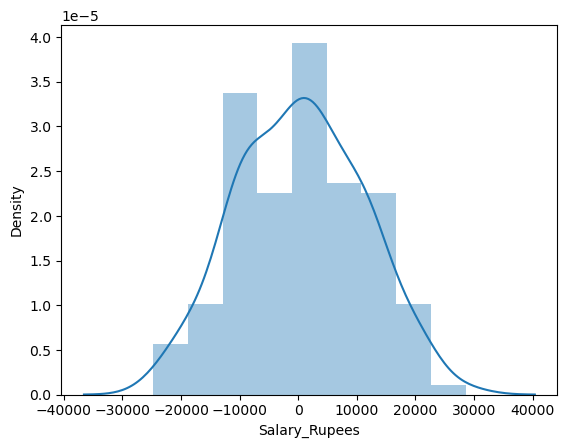

In [67]:
sns.distplot(residual)

###### Homoscedasticity
Constant variance of residuals across all levels of X (errors have equal spread).

Breusch–Pagan Test

In [68]:
from statsmodels.stats.diagnostic import het_breuschpagan

In [69]:
#H0 : The residuals have constant variance (i.e.Homoscedasticity present) 
#H1 : The residuals have non-constant variance (i.e., Hetroscedasticity present)

residuals = ytest-lr_pred
exog = sm.add_constant(xtest)
het_breuschpagan(residuals, exog)
p_val = 0.2907510539285842
p_val < 0.05
# Sicne p_val is not less than 0.05 we fail to reject H0.

False

##### Regularization 

Regularization is a technique used to prevent overfitting in regression or machine learning models by penalizing large coefficients.

➡️ It adds a penalty term to the model’s cost function (loss function), discouraging the model from relying too heavily on any one predictor

###### Train Error

In [71]:
train_pred = LR.predict(xtrain)
train_error = np.sqrt(mean_squared_error(ytrain,train_pred))
train_error

np.float64(9549.58675107077)

###### Test Error

In [73]:
test_pred = LR.predict(xtest)
test_error = np.sqrt(mean_squared_error(ytest,test_pred))
test_error

np.float64(10693.671240944554)

###### Variance Error 

If error on train is very low and error on test is very high its Variance error and Over Fit Model.

###### Bias Error

If error on train & test  is very low its Bias error and Under Fit Model.

###### Lasso 
Lasso regression, also known as L1 regularization, adds a penalty equal to the absolute value of the magnitude of coefficients to the loss function. It can shrink some coefficients exactly to zero, thereby performing variable selection in addition to regularization.

In [74]:
from sklearn.linear_model import Lasso,Ridge,ElasticNet

In [76]:
lasso = Lasso()
lasso.fit(xtrain,ytrain)
lasso_pred = lasso.predict(xtest)
print('RMSE',np.sqrt(mean_squared_error(ytest,lasso_pred)))

RMSE 10694.630473351592


###### Ridge

Ridge regression, also known as L2 regularization, is a technique that adds a penalty equal to the square of the magnitude of coefficients to the loss function. It helps to reduce model complexity and multicollinearity by shrinking the regression coefficients toward zero but never exactly zero.

In [78]:
ridge = Ridge()
ridge.fit(xtrain,ytrain)
ridge_pred = ridge.predict(xtest)
print('RMSE',np.sqrt(mean_squared_error(ytest,ridge_pred)))

RMSE 10715.5301630022


###### Elastic Net
Elastic Net regression is a combination of L1 (Lasso) and L2 (Ridge) regularization techniques. It adds both penalties to the loss function, balancing coefficient shrinkage and variable selection, making it suitable when predictors are highly correlated.

In [80]:
en = ElasticNet()
en.fit(xtrain,ytrain)
en_pred = en.predict(xtest)
print('RMSE',np.sqrt(mean_squared_error(ytest,en_pred)))

RMSE 13453.629208612549


##### Cross Validation

In [81]:
from sklearn.model_selection import cross_val_score

In [82]:
cross_val_score(estimator=LR,X=x,y=y,cv=5,n_jobs=-1)

array([0.95133825, 0.9478927 , 0.94923702, 0.93870545, 0.94007353])

##### Grid Search 

In [228]:
from sklearn.model_selection import GridSearchCV

In [238]:
en = ElasticNet()
params = {'l1_ratio':[0.1,0.2,0.3,0.4,0.5],'alpha':[0.1,0.2,0.3,0.4,0.5]}
en_grid = GridSearchCV(estimator=en,param_grid=params,cv=3,n_jobs=-1,scoring='neg_mean_absolute_error')
en_grid.fit(x,y)

GridSearchCV(cv=3, estimator=ElasticNet(), n_jobs=-1,
             param_grid={'alpha': [0.1, 0.2, 0.3, 0.4, 0.5],
                         'l1_ratio': [0.1, 0.2, 0.3, 0.4, 0.5]},
             scoring='neg_mean_absolute_error')

In [239]:
en_grid.best_params_

{'alpha': 0.1, 'l1_ratio': 0.5}

In [240]:
en_tuned = ElasticNet(alpha=0.1,l1_ratio=0.5)
en_tuned.fit(xtrain,ytrain)
en_tuned_pred = en_tuned.predict(xtest)
print('RMSE',np.sqrt(mean_squared_error(ytest,en_tuned_pred)))

RMSE 10821.0113363994


##### Gradient Descent 

In [242]:
from sklearn.linear_model import SGDRegressor

In [243]:
SGD = SGDRegressor()
SGD.fit(xtrain,ytrain)
sgd_pred = SGD.predict(xtest)
print('RMSE',np.sqrt(mean_squared_error(ytest,sgd_pred)))

RMSE 25537845044235.715
